> **이 노트북의 출력은 새로 통째로 받은 데이터(`data\통합_전체_202611`)로 지금 코드로 다시 돌린 결과다(2026-11-05).** 같은 실험을 더 넓게 한 것은 `확장연구_20261103.ipynb`다. 요약표용 결과는 `결과_월수익률/연구_이로운_*.pkl`, 예전 합친 데이터(2026-11-02) 결과는 `결과_월수익률/_예전_20261102/`에 있다.

# 이로운: 팩터 순서 (순위 합산 vs 단계별 거르기)
연구_틀(`연구_틀.ipynb`)을 복사해 **0번(실험 기록)과 3번(설정) 칸만** 바꾸고, 10번부터 실험 칸을 더했다. 공통 계산(`공통/`)은 이 노트북에서 바꾸지 않는다.

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW는 회원 결정(2026-11-06)으로 뺌, t는 OLS, TR(배당 포함 수정주가).

## 0. 실험 기록 [바꾸는 칸]
누가, 언제, 무엇을 왜 바꾸는지 적는다. 저장 파일 이름(이름_날짜_실험명.csv)에 쓰인다.

In [1]:
실험 = dict(
    이름="이로운",
    날짜="2026-11-02",
    실험명="팩터순서",
    무엇을="ROC·EY 순위 합산(마법공식)과, 한 지표로 먼저 상위 50%·30%를 거른 뒤 다른 지표로 30종목을 고르는 단계별 방식을 비교",
    왜="두 지표를 어떤 순서로 쓰느냐(합산 vs 거르기, 무엇을 먼저)가 결과를 바꾸는지 보려고. 종목 수는 모두 30으로 같게",
)

## 1. 데이터 경로 [바꾸는 칸]
기본은 새로 통째로 받은 파일(`data\통합_전체_202611`)이다. 시험 데이터로 빨리 볼 때만 주석을 푼다.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import 데이터읽기 as 읽기
# 시험 데이터로 빨리 볼 때: 읽기.DATA = Path.cwd().parent / "_시험데이터"
print(읽기.DATA)

D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611


## 2. 공통 불러오기 [건드리지 않는 칸]

In [3]:
import json
import pandas as pd
import 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

## 3. 설정 [바꾸는 칸]
`포.기본설정`에서 바꿀 것만 적는다. 쓸 수 있는 값:
- 시장: `"KS"`(유가증권), `"KQ"`(코스닥) / 기준일: `"첫거래일"`, `"마지막거래일"` / 리밸런싱: 1·3·12(달)
- 제외: `종목거르기.py`의 함수 이름 — 보통주, 스팩, 금융업, 투자기구, 결산월, 거래정지, 관리종목, 동전주, 자본잠식, 회전율, 거래대금, 시총상위, 시총분위, 종목빼기 (옵션은 `("이름", {옵션})`). `시장`과 `쓰지말것`(README_데이터 '쓰지 말 것' 구간)은 항상 먼저 적용된다
- 지표와 방향: `지표.py`의 함수 이름 + `"높게"`/`"낮게"` (단계별이면 셋째 값 = 남길 비율)
- 합산: `"순위합산"`, `"z합산"`, `"단계별"` / 고르기: `("상위N", n)`, `("분위", k)`
- 재무시점: `("결산후개월", k)`(결산일 + k개월, 발표일 안 봄) | `("발표일", k)`(발표일 다음 거래일, 없으면 결산일 + k일. k = 150 본문, 180 확인)
- 비중: `"동일"`, `"시총"`, `"시총상한"`(비중상한), `"시총상한10"`·`"시총상한30"`, `"위험균형"`(직전 12개월 변동성 역수), `"최소분산"`(공매도 없음, 직전 36개월 월수익률, Ledoit-Wolf 수축) / 거래비용: 수수료·거래세·슬리피지(·월비용) / 전량교체: `True`면 리밸런싱 때 전부 팔고 새로 삼(우동호 원문), `False`면 바뀐 만큼만

In [4]:
설정 = {**포.기본설정,
    "이름": 실험["실험명"],
    "기간": ("1990-04", "2026-09"),  # 백테스트 시작 1990(1988~89 배당 포함 수정주가 없음), 4월 리밸런싱
    "시장": ["KS", "KQ"],
    "기준일": "첫거래일",
    "리밸런싱": 12,
    "재무시점": ("발표일", 150),  # 1999년 이전은 발표일 기록이 거의 없어 결산일 + 150일(통합_확인기록 F8)
    "제외": ["보통주", "금융업", "투자기구", ("결산월", {"월": 12}), "거래정지"],
    "고르기": ("상위N", 30),
    "거래비용": dict(수수료=0.00015, 거래세=0.0025, 슬리피지=0.005),
    "지표": [("ROC", "높게"), ("EY", "높게")],  # 기준: 순위 합산
    "합산": "순위합산",
    "비중": ["동일", "시총"],
}
# 비교할 순서(지표, 합산). 단계별: (지표, 방향, 남길 비율) — 앞 지표로 상위 비율만 남기고 마지막 지표로 줄 세워 상위 30
순서 = {"순위합산(기준)": dict(지표=[("ROC", "높게"), ("EY", "높게")], 합산="순위합산"),
       "ROC 상위50% → EY": dict(지표=[("ROC", "높게", 0.5), ("EY", "높게", 1.0)], 합산="단계별"),
       "ROC 상위30% → EY": dict(지표=[("ROC", "높게", 0.3), ("EY", "높게", 1.0)], 합산="단계별"),
       "EY 상위50% → ROC": dict(지표=[("EY", "높게", 0.5), ("ROC", "높게", 1.0)], 합산="단계별"),
       "EY 상위30% → ROC": dict(지표=[("EY", "높게", 0.3), ("ROC", "높게", 1.0)], 합산="단계별")}

## 4. 새 지표 [바꾸는 칸]
이 실험은 새 지표를 만들지 않는다(`공통/지표.py`의 함수만 씀).

In [5]:
# 새 지표 없음

## 5. 실행 [건드리지 않는 칸]

In [6]:
결과 = 포.실행(설정)
F = 평가.요인(포.기준일(결과["설정"]), 결과["설정"])
R = pd.DataFrame({f"{b}_{g}": 결과["수익률"][(b, g)] for b, g in 결과["수익률"]})
if 설정["고르기"][0] == "분위":  # LS는 거래비용 0으로 다시 돌려 만든다(비용 뺀 Q5를 빼면 숏 쪽 비용 부호가 거꾸로 됨)
    g = 포.실행({**설정, "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)})["수익률"]
    for b in 설정["비중"]:
        R[f"{b}_LS(비용0)"] = g[(b, "Q1")] - g[(b, f"Q{설정['고르기'][1]}")]
R["시장"] = F["시장"]
R = R.dropna(how="all")

## 6. 결과표·누적수익률 그림 [건드리지 않는 칸]

,이상값 보유,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),...,FF3 t(NW보정),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart t(NW보정),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
동일_상위30,1.0000,437.0000,43.8205,0.1101,0.3335,0.2957,-0.7191,0.2132,0.0082,1.7845,...,2.1002,0.0072,2.6049,1.8669,1.8560,0.8790,0.9421,-0.2555,0.0655,0.6609
시총_상위30,1.0000,437.0000,8.8678,0.0649,0.3629,0.1862,-0.7309,0.1137,0.0056,1.1234,...,0.9802,0.0029,0.7784,0.8435,0.8386,0.9713,0.4460,-0.0999,0.1005,0.4864
시장,NaN,437.0000,7.1545,0.0593,0.2697,0.1327,-0.7243,NaN,0.0030,0.8005,...,NaN,0.0000,NaN,NaN,NaN,1.0000,-0.0000,-0.0000,-0.0000,1.0000


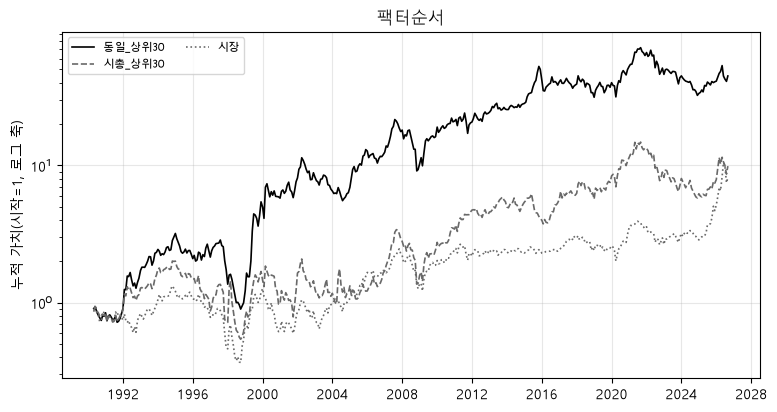

In [7]:
표 = 평가.성과표(R, F, [c for c in R if "_LS" in c])
표.insert(0, "이상값 보유", pd.Series({f"{b}_{g}": n for (b, g), n in 포.이상값보유(결과).items()}))  # +300% 종목-월 보유 건수(README 한계 '이상값 보유 칸')
평가.누적그림(R, 설정["이름"]);
표

## 7. 같은 기간 기준과 자동 비교 [건드리지 않는 칸]
같은 기간으로 우동호(2023) 재현과 시장을 돌려 나란히 놓는다. 무위험이자율과 전량교체 여부는 3번 칸 설정 것을 쓴다.
기준은 두 줄이다. **본문 설정**은 우동호 그대로(배당 빠진 수정주가, 결산 후 3개월), **같은 가격·재무시점**은 가격 계열과 재무시점까지 3번 칸 설정에 맞춘 것. 두 기준의 차이는 배당 포함 여부와 재무시점 차이에서 나온다. 실험 효과는 '같은 가격·재무시점' 줄과 비교한다.
기간 안에서 개월 수가 다를 수 있다(개월 칸 확인. 첫 리밸런싱에 종목이 없으면 그 구간은 빈칸).

In [8]:
기준 = {**포.우동호2023, "기간": 설정["기간"], "무위험": 설정["무위험"], "전량교체": 설정["전량교체"]}
기준들 = {f"기준:{기준['이름']}(본문 설정)": 기준, f"기준:{기준['이름']}(같은 가격·재무시점)": {**기준, "가격": 설정["가격"], "재무시점": 설정["재무시점"]}}
Fb = 평가.요인(포.기준일(기준), 기준)
기준표 = 평가.성과표(pd.DataFrame({k: 포.실행(v)["수익률"][("동일", "상위30")] for k, v in 기준들.items()} | {"기준:시장": Fb["시장"]}).dropna(how="all"), Fb)
비교 = pd.concat([표, 기준표])
비교[["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "정보비율", "Carhart α(월)", "Carhart t(OLS)"]]

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,Carhart α(월),Carhart t(NW)
동일_상위30,437.0000,43.8205,0.1101,0.3335,0.2957,-0.7191,0.2132,0.0072,1.8669
시총_상위30,437.0000,8.8678,0.0649,0.3629,0.1862,-0.7309,0.1137,0.0029,0.8435
시장,437.0000,7.1545,0.0593,0.2697,0.1327,-0.7243,NaN,0.0000,NaN
기준:우동호2023_MF(본문 설정),437.0000,23.3704,0.0916,0.3102,0.2472,-0.6222,0.1504,0.0045,1.1222
기준:우동호2023_MF(같은 가격·재무시점),437.0000,43.8205,0.1101,0.3335,0.2957,-0.7191,0.2132,0.0072,1.8669
기준:시장,437.0000,7.1545,0.0593,0.2697,0.1327,-0.7243,NaN,0.0000,NaN


## 8. 확인 [건드리지 않는 칸]
리밸런싱마다 단계별 남은 종목 수, 지표별 빈칸 수, 빈칸 때문에 빠진 수, 편입 수.

In [9]:
결과["기록"].T

기준일,1990-04-02,1991-04-01,1992-04-01,1993-04-01,1994-04-01,1995-04-01,1996-04-01,1997-04-01,1998-04-01,1999-04-01,...,2017-04-03,2018-04-02,2019-04-01,2020-04-01,2021-04-01,2022-04-01,2023-04-03,2024-04-01,2025-04-01,2026-04-01
가격있음,729,773,784,793,802,848,885,1270,1308,1239,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
시장,729,773,784,793,802,848,885,1270,1308,1239,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
쓰지말것,729,773,784,793,802,848,885,1270,1308,1239,...,2110,2162,2237,2330,2419,2496,2579,2675,2756,2773
보통주,607,639,645,653,662,690,720,1081,1131,1056,...,1992,2044,2121,2210,2298,2373,2456,2558,2640,2660
금융업,522,553,558,566,574,595,624,931,988,944,...,1865,1851,1915,2021,2106,2179,2247,2335,2402,2437
투자기구,522,553,558,566,574,595,624,931,988,944,...,1842,1841,1903,2008,2090,2158,2224,2312,2379,2414
결산월,433,462,468,478,488,508,536,816,871,825,...,1802,1805,1866,1968,2050,2120,2187,2276,2346,2384
거래정지,433,462,468,478,488,506,533,815,867,812,...,1766,1767,1807,1874,1948,2024,2126,2191,2260,2292
빈칸:ROC,86,90,91,81,86,84,87,245,247,209,...,147,147,151,40,33,32,39,46,51,52
빈칸:EY,9,5,3,7,12,10,9,75,71,44,...,124,124,132,20,14,14,14,24,27,28


## 9. 저장 [건드리지 않는 칸]
설정과 결과를 `연구/결과/이름_날짜_실험명.csv`에 남긴다. 같은 이름이 있으면 뒤에 번호를 붙인다(덮어쓰지 않음).

In [10]:
out = Path.cwd() / "결과"
f = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}.csv"
i = 1
while f.exists():
    f, i = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}_{i}.csv", i + 1
비교.assign(실험기록=json.dumps(실험, ensure_ascii=False), 설정=json.dumps(설정, ensure_ascii=False, default=str)).to_csv(f, encoding="utf-8-sig")
print("저장:", f)

저장: D:\26-2_데이터기반투자전략\과제02\과제02_백테스트\연구\결과\이로운_2026-11-02_팩터순서_3.csv


## 10. 순서별 실행 [실험 칸]
첫 표: 리밸런싱마다 편입 종목 수의 최솟값·최댓값(모두 30이어야 같은 조건). 둘째 표: 순위합산 포트폴리오와 겹치는 종목 수. 셋째 표: 성과.

,min,max
편입 종목 수,,
순위합산(기준),30,30
ROC 상위50% → EY,30,30
ROC 상위30% → EY,30,30
EY 상위50% → ROC,30,30
EY 상위30% → ROC,30,30


,mean,min,max
순위합산과 겹치는 종목 수,,,
순위합산(기준),30.0000,30.0000,30.0000
ROC 상위50% → EY,18.0270,12.0000,25.0000
ROC 상위30% → EY,19.3243,14.0000,25.0000
EY 상위50% → ROC,17.4054,10.0000,26.0000
EY 상위30% → ROC,19.2432,12.0000,27.0000


개월       누적    연환산  표준편차(연)     샤프     MDD   정보비율  초과평균 α(월)  초과평균 t(OLS)  초과평균 t(NW)  ...  FF3 t(NW보정)  Carhart α(월)  Carhart t(OLS)  Carhart t(NW)  Carhart t(NW보정)  Carhart β:MKT  \
순위합산(기준)       동일 437.0000  43.8205 0.1101   0.3335 0.2957 -0.7191 0.2132     0.0082       1.7845      1.5507  ...       2.1002        0.0072          2.6049         1.8669           1.8560         0.8790   
               시총 437.0000   8.8678 0.0649   0.3629 0.1862 -0.7309 0.1137     0.0056       1.1234      1.1467  ...       0.9802        0.0029          0.7784         0.8435           0.8386         0.9713   
ROC 상위50% → EY 동일 437.0000 176.9613 0.1529   0.3221 0.4163 -0.6478 0.3446     0.0112       2.5124      2.1091  ...       2.6192        0.0092          3.3553         2.4695           2.4552         0.8558   
               시총 437.0000  47.8887 0.1127   0.3410 0.3063 -0.6046 0.2689     0.0087       1.8485      1.7637  ...       1.5672        0.0047          1.4617         1.5580           1.5490         0.9737   
ROC 상위30% → EY 동일 437.0000 115.5650 0.1396   0.3229 0.3791 -0.6658 0.3021     0.0102       2.2878      1.9705  ...       2.4415        0.0084          3.0560         2.3048           2.2914         0.8545   
               시총 437.0000  28.8124 0.0977   0.3327 0.2679 -0.6942 0.2146     0.0074       1.6167      1.5220  ...       1.2071        0.0037          1.1970         1.1999           1.1930         0.9509   
EY 상위50% → ROC 동일 437.0000   6.7804 0.0580   0.3190 0.1475 -0.7501 0.0415     0.0039       0.8904      0.7997  ...       1.1349        0.0028          1.1224         0.9261           0.9208         0.8931   
               시총 437.0000  24.7307 0.0933   0.3871 0.2599 -0.7492 0.2593     0.0084       1.5685      1.4141  ...       1.8602        0.0051          1.5330         1.5770           1.5679         1.1494   
EY 상위30% → ROC 동일 437.0000   9.2213 0.0659   0.3255 0.1714 -0.7309 0.0717     0.0047       1.0341      0.9182  ...       1.2362        0.0035          1.3504         1.0257           1.0198         0.8960   
               시총 437.0000  15.6949 0.0804   0.3888 0.2271 -0.7426 0.2010     0.0074       1.3704      1.2218  ...       1.3970        0.0037          1.0573         1.0525           1.0464         1.1157   

                   Carhart β:SMB  Carhart β:HML  Carhart β:MOM  Carhart adj R²  
순위합산(기준)       동일         0.9421        -0.2555         0.0655          0.6609  
               시총         0.4460        -0.0999         0.1005          0.4864  
ROC 상위50% → EY 동일         0.8969        -0.1107         0.0299          0.6418  
               시총         0.5328         0.0673         0.0546          0.5602  
ROC 상위30% → EY 동일         0.9036        -0.1318         0.0266          0.6423  
               시총         0.5091         0.0378         0.0463          0.5587  
EY 상위50% → ROC 동일         0.8694        -0.2577         0.0712          0.6952  
               시총         0.2066        -0.1822         0.2698          0.6314  
EY 상위30% → ROC 동일         0.8878        -0.2597         0.0757          0.6812  
               시총         0.1961        -0.1394         0.2851          0.5916  

[10 rows x 28 columns]

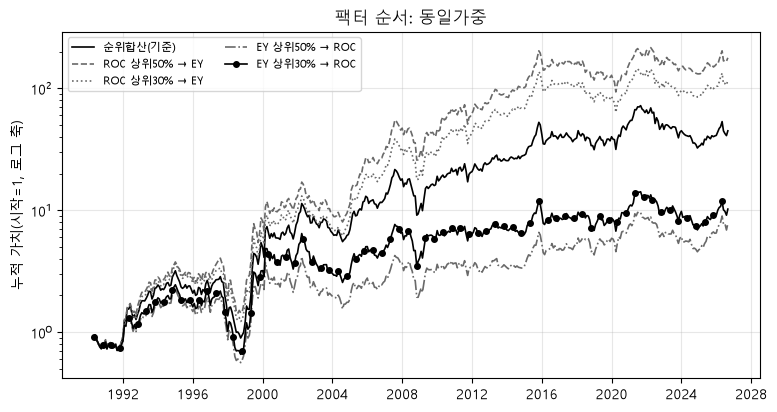

In [11]:
순서결과 = {k: 결과 if k == "순위합산(기준)" else 포.실행({**설정, "이름": k, **v}) for k, v in 순서.items()}
display(pd.DataFrame({k: o["기록"]["편입:상위30"].agg(["min", "max"]) for k, o in 순서결과.items()}).T.rename_axis("편입 종목 수"))
기준W = 결과["보유"][("동일", "상위30")]
display(pd.DataFrame({k: pd.Series({t: len(w.index.intersection(기준W[t].index)) for t, w in o["보유"][("동일", "상위30")].items()}) for k, o in 순서결과.items()})
        .agg(["mean", "min", "max"]).T.rename_axis("순위합산과 겹치는 종목 수"))
X = pd.DataFrame({(k, w): o["수익률"][(w, "상위30")] for k, o in 순서결과.items() for w in 설정["비중"]}).dropna(how="all")
평가.누적그림(X.xs("동일", axis=1, level=1), "팩터 순서: 동일가중");
평가.성과표(X, F)

## 11. 요약표용 저장 [실험 칸]

In [12]:
S = X.copy()
S.columns = pd.MultiIndex.from_tuples([(f"팩터순서 {k}", w) for k, w in S])
평가.저장(S, F, "연구_이로운_팩터순서", 이상값={(f"팩터순서 {k}", w): 포.이상값보유(o)[(w, "상위30")] for k, o in 순서결과.items() for w in 설정["비중"]})
list(S)

[('팩터순서 순위합산(기준)', '동일'),
 ('팩터순서 순위합산(기준)', '시총'),
 ('팩터순서 ROC 상위50% → EY', '동일'),
 ('팩터순서 ROC 상위50% → EY', '시총'),
 ('팩터순서 ROC 상위30% → EY', '동일'),
 ('팩터순서 ROC 상위30% → EY', '시총'),
 ('팩터순서 EY 상위50% → ROC', '동일'),
 ('팩터순서 EY 상위50% → ROC', '시총'),
 ('팩터순서 EY 상위30% → ROC', '동일'),
 ('팩터순서 EY 상위30% → ROC', '시총')]